# 1. Chuẩn bị môi trường và dữ liệu

### 1.1 Import thư viện và kiểm tra môi trường

In [2]:
import os, math, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", device, "|", torch.cuda.get_device_name(0) if use_amp else "KHÔNG CÓ GPU !") # thông báo chương trình hiện không chạy bằng GPU
print(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset"))

Device: cuda | Tesla T4
['color', 'grayscale', 'plantvillage dataset', 'segmented']


### 1.2 dataset và cấu hình

In [3]:
DATA_DIR      = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color" # thư mục ảnh màu của dataset
IMG_SIZE      = 128     # Resize toàn bộ ảnh về 128×128 (đồng nhất)
N_PER_CLASS   = 20      # số ảnh CÓ NHÃN mỗi lớp (chỉ lấy 20)
TEST_RATIO    = 0.20    # số lượng test 20%
EPOCHS_SMALL  = 40      # số epochs tập nhỏ
EPOCHS_LARGE  = 10       # số epochs tập lớn
CONF_THRESH   = 0.90    # ngưỡng tin cậy để nhận nhãn tự động (>90% mới đủ tin cậy)
ROT_DEG       = 30      # góc xoay tối đa khi augmentation (Tham số cho augmentation hình học)

### 1.3 Nạp ảnh vào bộ nhớ GPU

In [4]:
# Decoder toàn bộ ảnh một lần và giữ trên GPU
tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.PILToTensor(),          
])
ds = datasets.ImageFolder(DATA_DIR, transform=tf)
class_names = ds.classes
num_classes = len(class_names)

loader = DataLoader(ds, batch_size=256, num_workers=4, shuffle=False)
xs, ys = [], []
for x, y in tqdm(loader):
    xs.append(x); ys.append(y)

X = torch.cat(xs).to(device)           # (N,3,H,W) uint8 trên GPU
Y = torch.cat(ys)                      # nhãn thật (CPU)
Y_gpu = Y.to(device)
print("Số ảnh:", X.shape, "| Số lớp:", num_classes, "| Bộ nhớ GPU ~", round(X.numel()/1e9, 2), "GB")

  0%|          | 0/213 [00:00<?, ?it/s]

Số ảnh: torch.Size([54305, 3, 128, 128]) | Số lớp: 38 | Bộ nhớ GPU ~ 2.67 GB


### 1.4 Khám phá dữ liệu  (EDA)

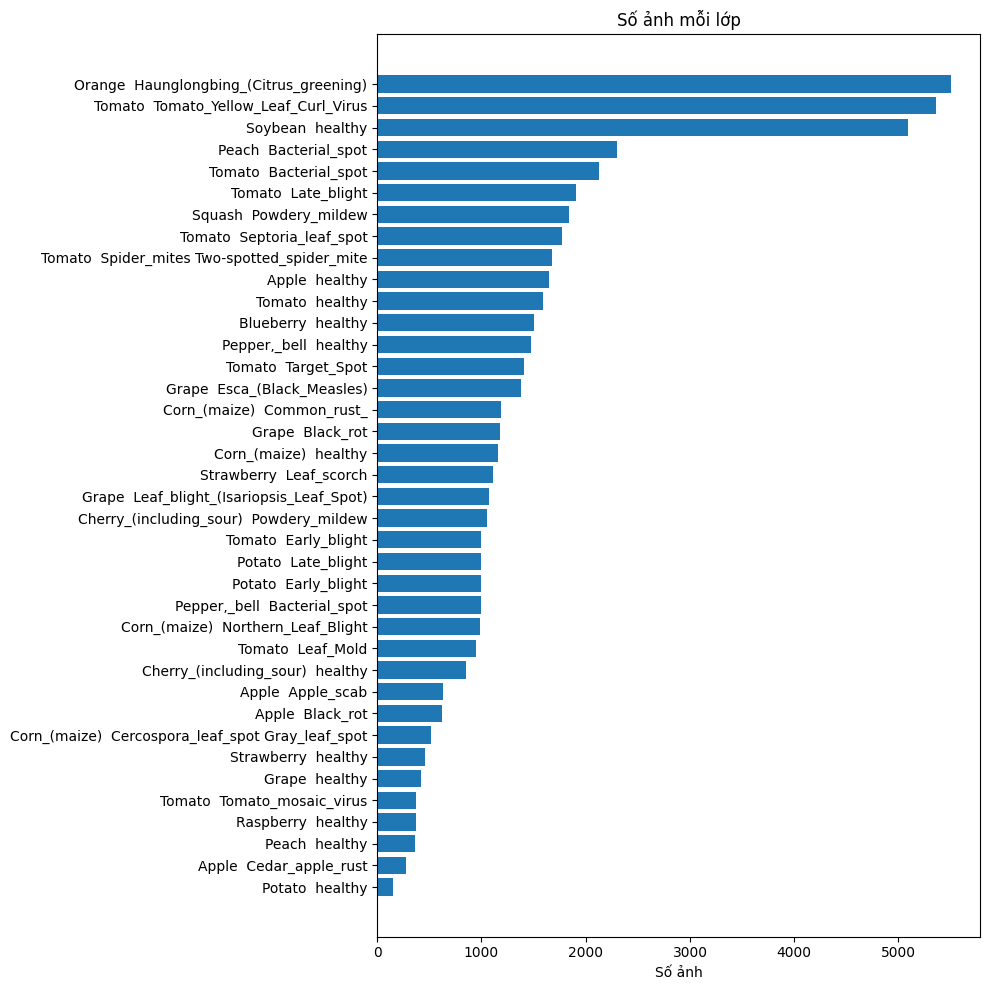

Lớp ít nhất: 152 | nhiều nhất: 5507


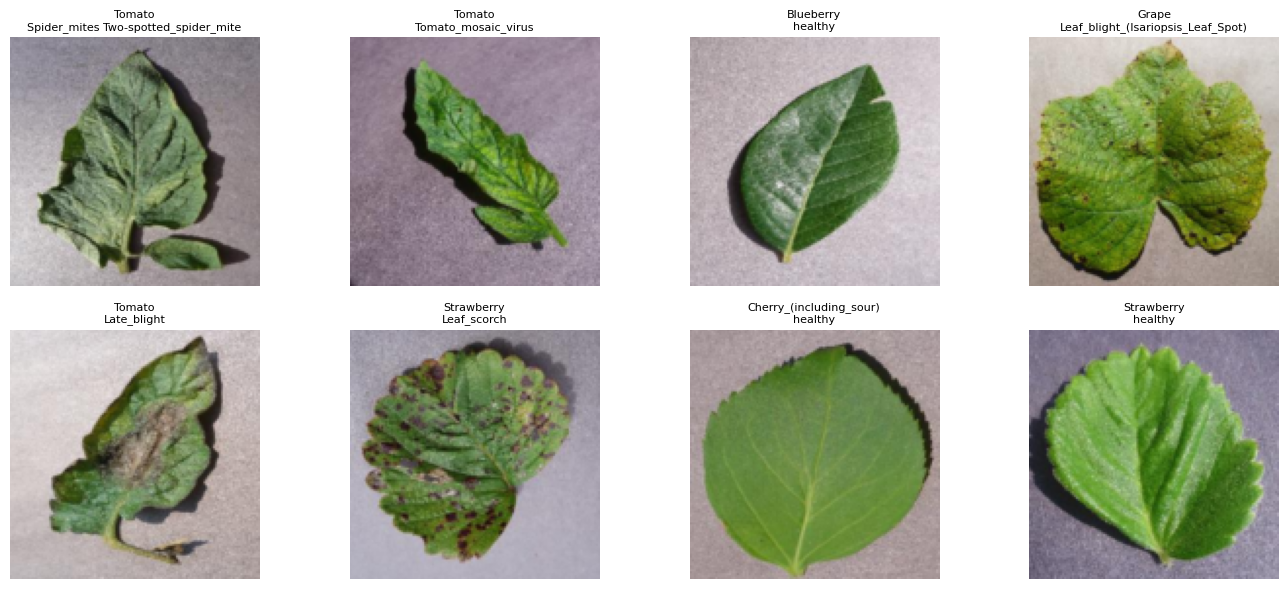

In [5]:
counts = np.bincount(Y.numpy(), minlength=num_classes)
order = np.argsort(counts) # sắp xếp tăng dần

plt.figure(figsize=(10, 10))
plt.barh([class_names[i].replace("___", "  ") for i in order], counts[order]) # bỏ các phần gạch chân phía dưới tên -> làm tên mẫu dễ đọc hơn
plt.title("Số ảnh mỗi lớp"); plt.xlabel("Số ảnh"); plt.tight_layout(); plt.show()
print("Lớp ít nhất:", counts.min(), "| nhiều nhất:", counts.max())

# Ảnh minh họa (8 lớp - mỗi lớp 1 mẫu)
plt.figure(figsize=(14, 6))
for k, c in enumerate(np.random.choice(num_classes, 8, replace=False)):
    i = np.random.choice(np.where(Y.numpy() == c)[0])
    plt.subplot(2, 4, k + 1)
    plt.imshow(X[i].permute(1, 2, 0).cpu())
    plt.title(class_names[c].replace("___", "\n"), fontsize=8); plt.axis("off")
plt.tight_layout(); plt.show()

### 1.5 Chia dữ liệu thành có nhãn / chưa nhãn / test

In [6]:
rng = np.random.RandomState(SEED)
Y_np = Y.numpy()
perm = rng.permutation(len(Y_np))

n_test = int(TEST_RATIO * len(Y_np))
test_idx = perm[:n_test]
pool_idx = perm[n_test:]

labeled_idx = []
for c in range(num_classes):
    ids = pool_idx[Y_np[pool_idx] == c]
    labeled_idx.extend(ids[:N_PER_CLASS])
labeled_idx = np.array(labeled_idx)
unlabeled_idx = np.setdiff1d(pool_idx, labeled_idx)

print(f"Có nhãn: {len(labeled_idx)} | Chưa nhãn: {len(unlabeled_idx)} | Test: {len(test_idx)}")
print(f"Tỉ lệ có nhãn trong pool: {len(labeled_idx)/len(pool_idx):.2%}")

Có nhãn: 760 | Chưa nhãn: 42684 | Test: 10861
Tỉ lệ có nhãn trong pool: 1.75%


# 2. Xây dựng công cụ chính

### 2.1 Data augmentation trên GPU

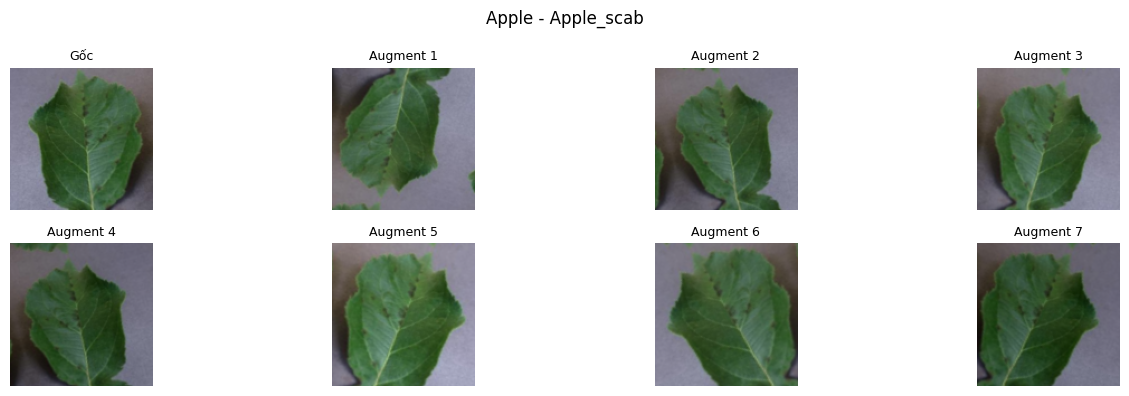

In [7]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def normalize(x):               # x: float [0,1]
    return (x - MEAN) / STD

# Hàm augmentation
def gpu_augment(x):
    """x: (B,3,H,W) float [0,1]. Mỗi ảnh có tham số ngẫu nhiên riêng."""
    B = x.size(0)
    # 1) Lật ngang / dọc
    fh = (torch.rand(B, device=device) < 0.5).view(B, 1, 1, 1)
    fv = (torch.rand(B, device=device) < 0.5).view(B, 1, 1, 1)
    x = torch.where(fh, x.flip(3), x)
    x = torch.where(fv, x.flip(2), x)
    # 2) Xoay + zoom + dịch chuyển (affine)
    ang   = (torch.rand(B, device=device) * 2 - 1) * math.radians(ROT_DEG)
    scale = 1 + (torch.rand(B, device=device) * 2 - 1) * 0.15
    tx    = (torch.rand(B, device=device) * 2 - 1) * 0.10
    ty    = (torch.rand(B, device=device) * 2 - 1) * 0.10
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1),
                         torch.stack([sin,  cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="reflection", align_corners=False)
    # 3) Độ sáng / độ tương phản
    b = (1 + (torch.rand(B, device=device) * 2 - 1) * 0.2).view(B, 1, 1, 1)
    c = (1 + (torch.rand(B, device=device) * 2 - 1) * 0.2).view(B, 1, 1, 1)
    x = x * b
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * c + m
    return x.clamp(0, 1)

# Minh họa: 1 ảnh gốc và 7 ảnh augmentation (các ảnh là biến thể của 1 ảnh gốc)
i = int(labeled_idx[0])
orig = X[i].float().div(255).unsqueeze(0)
aug = gpu_augment(orig.repeat(8, 1, 1, 1))
plt.figure(figsize=(14, 4))
for k in range(8):
    plt.subplot(2, 4, k + 1)
    img = orig[0] if k == 0 else aug[k]
    plt.imshow(img.permute(1, 2, 0).cpu()); plt.axis("off")
    plt.title("Gốc" if k == 0 else f"Augment {k}", fontsize=9)
plt.suptitle(class_names[Y_np[i]].replace("___", " - ")); plt.tight_layout(); plt.show()

### 2.2 Hàm tạo mô hình, huấn luyện và dự đoán

In [8]:
def make_model():
    try:
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    except Exception as e:
        print("Không tải được pretrained, train từ đầu:", e)
        m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m.to(device)

def train_model(idx, labels, epochs, augment, bs=64, lr=1e-3, name=""):
    model = make_model()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = math.ceil(len(idx) / bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs, steps_per_epoch=steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    idx_t = torch.as_tensor(idx, device=device)
    lab_t = torch.as_tensor(labels, device=device).long()

    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(idx_t), device=device)
        tot_loss, correct, n = 0.0, 0, 0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            if len(b) < 2: continue
            xb = X[idx_t[b]].float().div(255)
            if augment: xb = gpu_augment(xb)
            xb, yb = normalize(xb), lab_t[b]
            with torch.amp.autocast("cuda", enabled=use_amp):
                out = model(xb); loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot_loss += loss.item() * len(b); correct += (out.argmax(1) == yb).sum().item(); n += len(b)
        if ep % max(1, epochs // 5) == 0 or ep == epochs:
            print(f"[{name}] epoch {ep}/{epochs} | loss {tot_loss/n:.4f} | train accuracy {correct/n:.4f}")
    print(f"[{name}] xong sau {time.time()-t0:.0f}s")
    return model

@torch.no_grad()
def predict_proba(model, idx, tta=False, bs=512):
    model.eval()
    idx_t = torch.as_tensor(idx, device=device)
    outs = []
    for i in range(0, len(idx_t), bs):
        x = X[idx_t[i:i + bs]].float().div(255)
        views = [x]
        if tta:   # 4 phiên bản biến đổi cố định
            views += [x.flip(3), x.flip(2), torch.rot90(x, 1, (2, 3)), torch.rot90(x, 3, (2, 3))]
        p = 0
        for v in views:
            with torch.amp.autocast("cuda", enabled=use_amp):
                p = p + torch.softmax(model(normalize(v)).float(), 1)
        outs.append((p / len(views)).cpu())
    return torch.cat(outs)

def test_acc(model):
    p = predict_proba(model, test_idx)
    return (p.argmax(1) == Y[test_idx]).float().mean().item()

results = {}

# 3. Thí nghiệm cơ sở dùng dữ liệu có nhãn

### *Lưu ý: mỗi thí nghiệm huấn luyện trên một phần dữ liệu khác nhau.*

### 3.1 Thí nghiệm 1 (không augmentation)

In [9]:
model1 = train_model(labeled_idx, Y_np[labeled_idx], EPOCHS_SMALL, augment=False, bs=32, name="TN1")
results["TN1: 760 ảnh, không augment"] = test_acc(model1)
print("Test accuracy:", results["TN1: 760 ảnh, không augment"])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s] 


[TN1] epoch 8/40 | loss 0.0086 | train accuracy 1.0000
[TN1] epoch 16/40 | loss 0.0016 | train accuracy 1.0000
[TN1] epoch 24/40 | loss 0.0008 | train accuracy 1.0000
[TN1] epoch 32/40 | loss 0.0007 | train accuracy 1.0000
[TN1] epoch 40/40 | loss 0.0006 | train accuracy 1.0000
[TN1] xong sau 21s
Test accuracy: 0.890433669090271


### 3.2 Thí nghiệm 2 (có augmentation)

In [10]:
model2 = train_model(labeled_idx, Y_np[labeled_idx], EPOCHS_SMALL, augment=True, bs=32, name="TN2")
results["TN2: 760 ảnh, có augment"] = test_acc(model2)
print("Test accuracy:", results["TN2: 760 ảnh, có augment"])

[TN2] epoch 8/40 | loss 0.5539 | train accuracy 0.8250
[TN2] epoch 16/40 | loss 0.3608 | train accuracy 0.8895
[TN2] epoch 24/40 | loss 0.0971 | train accuracy 0.9697
[TN2] epoch 32/40 | loss 0.0179 | train accuracy 0.9947
[TN2] epoch 40/40 | loss 0.0162 | train accuracy 0.9961
[TN2] xong sau 20s
Test accuracy: 0.928459644317627


# 4. Gán nhãn tự động cho dữ liệu chưa nhãn

### 4.1 Gán nhãn tự động và so sánh các cách gán

In [11]:
y_unl = Y[unlabeled_idx]

probs = {
    "TN1 (không augment)":          predict_proba(model1, unlabeled_idx, tta=False),
    "TN2 (augment)":                predict_proba(model2, unlabeled_idx, tta=False),
    "TN2 + TTA (augment + TTA)":    predict_proba(model2, unlabeled_idx, tta=True),
}

def label_stats(p, thr):
    conf, pred = p.max(1)
    m = conf >= thr
    cov = m.float().mean().item()
    acc = (pred[m] == y_unl[m]).float().mean().item() if m.any() else float("nan")
    return cov, acc

rows = []
for name, p in probs.items():
    acc_all = (p.argmax(1) == y_unl).float().mean().item()
    cov, acc = label_stats(p, CONF_THRESH)
    rows.append({"Cách gán nhãn": name,
                 "Acc nhãn (gán hết)": round(acc_all, 4),
                 f"Độ phủ (conf≥{CONF_THRESH})": round(cov, 4),
                 f"Acc nhãn (conf≥{CONF_THRESH})": round(acc, 4)})
pd.DataFrame(rows)

,Cách gán nhãn,Acc nhãn (gán hết),Độ phủ (conf≥0.9),Acc nhãn (conf≥0.9)
0,TN1 (không augment),0.8893,0.6865,0.9857
1,TN2 (augment),0.9266,0.8740,0.9760
2,TN2 + TTA (augment + TTA),0.9300,0.7301,0.9895


### 4.2 Biểu đồ độ phủ và độ chính xác của nhãn theo ngưỡng tin cậy

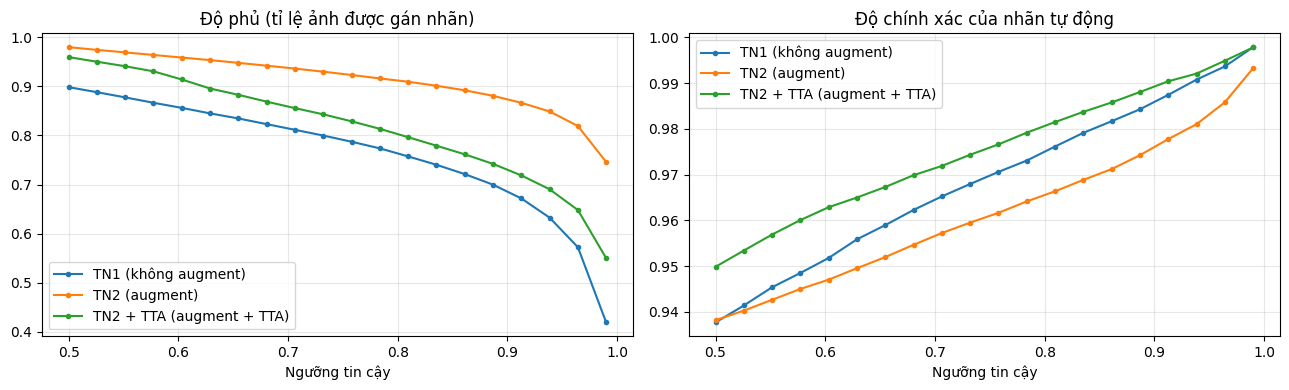

In [12]:
thrs = np.linspace(0.5, 0.99, 20)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, p in probs.items():
    st = [label_stats(p, t) for t in thrs]
    ax[0].plot(thrs, [s[0] for s in st], "o-", label=name, ms=3)
    ax[1].plot(thrs, [s[1] for s in st], "o-", label=name, ms=3)
ax[0].set_title("Độ phủ (tỉ lệ ảnh được gán nhãn)"); ax[1].set_title("Độ chính xác của nhãn tự động")
for a in ax: a.set_xlabel("Ngưỡng tin cậy"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

### 4.3 Chọn nhãn tự động (pseudo-labels)

In [13]:
p = probs["TN2 + TTA (augment + TTA)"]
conf, pred = p.max(1)
mask = (conf >= CONF_THRESH).numpy()

pseudo_idx    = unlabeled_idx[mask]
pseudo_labels = pred.numpy()[mask]
true_of_pseudo = Y_np[pseudo_idx]

print(f"Số ảnh được gán nhãn tự động: {len(pseudo_idx)} / {len(unlabeled_idx)} ({mask.mean():.2%})")
print(f"Độ chính xác của nhãn tự động: {(pseudo_labels == true_of_pseudo).mean():.4f}")
print(f"Số nhãn sai: {(pseudo_labels != true_of_pseudo).sum()}")

Số ảnh được gán nhãn tự động: 31165 / 42684 (73.01%)
Độ chính xác của nhãn tự động: 0.9895
Số nhãn sai: 327


# 5. Huấn luyện lại với nhãn tự động và mốc trần

### 5.1 Thí nghiệm 3 (dữ liệu có nhãn + nhãn tự động)

In [14]:
comb_idx    = np.concatenate([labeled_idx, pseudo_idx])
comb_labels = np.concatenate([Y_np[labeled_idx], pseudo_labels])   # nhãn tự động, KHÔNG dùng nhãn thật

model3 = train_model(comb_idx, comb_labels, EPOCHS_LARGE, augment=True, bs=64, name="TN3")
results["TN3: có nhãn + nhãn tự động"] = test_acc(model3)
print("Test accuracy:", results["TN3: có nhãn + nhãn tự động"])

[TN3] epoch 2/10 | loss 0.1517 | train accuracy 0.9540
[TN3] epoch 4/10 | loss 0.0967 | train accuracy 0.9699
[TN3] epoch 6/10 | loss 0.0487 | train accuracy 0.9850
[TN3] epoch 8/10 | loss 0.0159 | train accuracy 0.9951
[TN3] epoch 10/10 | loss 0.0049 | train accuracy 0.9985
[TN3] xong sau 179s
Test accuracy: 0.9164901971817017


### 5.2 Thí nghiệm 4, mốc trần (toàn bộ nhãn thật)

In [15]:
model4 = train_model(pool_idx, Y_np[pool_idx], EPOCHS_LARGE, augment=True, bs=64, name="TN4")
results["TN4: toàn bộ nhãn thật (mốc trần)"] = test_acc(model4)
print("Test accuracy:", results["TN4: toàn bộ nhãn thật (mốc trần)"])

[TN4] epoch 2/10 | loss 0.2144 | train accuracy 0.9316
[TN4] epoch 4/10 | loss 0.1403 | train accuracy 0.9540
[TN4] epoch 6/10 | loss 0.0714 | train accuracy 0.9769
[TN4] epoch 8/10 | loss 0.0268 | train accuracy 0.9915
[TN4] epoch 10/10 | loss 0.0103 | train accuracy 0.9964
[TN4] xong sau 244s
Test accuracy: 0.993370771408081


# 6. Tổng kết và phân tích

### 6.1 Biểu đồ tổng kết

,Thí nghiệm,Test accuracy
0,"TN1: 760 ảnh, không augment",0.8904
1,"TN2: 760 ảnh, có augment",0.9285
2,TN3: có nhãn + nhãn tự động,0.9165
3,TN4: toàn bộ nhãn thật (mốc trần),0.9934


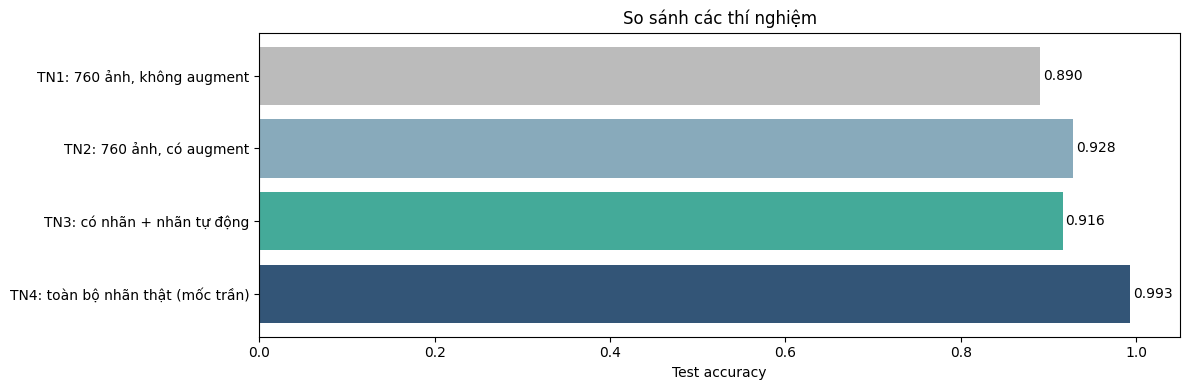

In [16]:
df = pd.DataFrame({"Thí nghiệm": list(results.keys()),
                   "Test accuracy": [round(v, 4) for v in results.values()]})
display(df)

plt.figure(figsize=(12, 4))
bars = plt.barh(df["Thí nghiệm"], df["Test accuracy"], color=["#bbb", "#8ab", "#4a9", "#357"])
for b, v in zip(bars, df["Test accuracy"]):
    plt.text(v + 0.003, b.get_y() + b.get_height()/2, f"{v:.3f}", va="center")
plt.xlim(0, 1.05); plt.xlabel("Test accuracy"); plt.gca().invert_yaxis()
plt.title("So sánh các thí nghiệm"); plt.tight_layout(); plt.show()

In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

y_true = Y[test_idx].numpy()
models_ = {"TN1": model1, "TN2": model2, "TN3": model3, "TN4": model4}

rows, preds = [], {}
for name, m in models_.items():
    pred = predict_proba(m, test_idx).argmax(1).numpy()
    preds[name] = pred
    rows.append({
        "Thí nghiệm": name,
        "Accuracy":           round((pred == y_true).mean(), 4),
        "Precision (macro)":  round(precision_score(y_true, pred, average="macro", zero_division=0), 4),
        "Recall (macro)":     round(recall_score(y_true, pred, average="macro", zero_division=0), 4),
        "F1 (macro)":         round(f1_score(y_true, pred, average="macro", zero_division=0), 4),
        "F1 (weighted)":      round(f1_score(y_true, pred, average="weighted", zero_division=0), 4),
    })
display(pd.DataFrame(rows))

,Thí nghiệm,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
0,TN1,0.8904,0.8442,0.8858,0.8556,0.8913
1,TN2,0.9285,0.9127,0.9306,0.9182,0.9285
2,TN3,0.9165,0.9150,0.9190,0.9097,0.9153
3,TN4,0.9934,0.9912,0.9922,0.9916,0.9934


In [18]:
y_true = Y[test_idx].numpy()
models_ = {"TN1": model1, "TN2": model2, "TN3": model3, "TN4": model4}

rows = []
for name, m in models_.items():
    pred = predict_proba(m, test_idx).argmax(1).numpy()
    dung = int((pred == y_true).sum())
    rows.append({
        "Thí nghiệm":   name,
        "Tổng ảnh test": len(y_true),
        "Đoán đúng":    dung,
        "Đoán sai":     len(y_true) - dung,
        "Accuracy":     round(dung / len(y_true), 4),
    })
display(pd.DataFrame(rows))

,Thí nghiệm,Tổng ảnh test,Đoán đúng,Đoán sai,Accuracy
0,TN1,10861,9671,1190,0.8904
1,TN2,10861,10084,777,0.9285
2,TN3,10861,9954,907,0.9165
3,TN4,10861,10789,72,0.9934


In [19]:
for EXP in ["TN1", "TN2", "TN3", "TN4"]:
    rep = classification_report(y_true, preds[EXP], labels=list(range(num_classes)),
                                target_names=class_names, output_dict=True, zero_division=0)
    df_rep = pd.DataFrame(rep).T.iloc[:num_classes]
    print(f"\n10 lớp có F1 thấp nhất ({EXP}):")
    display(df_rep.sort_values("f1-score")[["precision", "recall", "f1-score", "support"]].head(10))


10 lớp có F1 thấp nhất (TN1):


,precision,recall,f1-score,support
Potato___healthy,0.281250,0.720000,0.404494,25.0
Tomato___Early_blight,0.522613,0.488263,0.504854,213.0
Tomato___Septoria_leaf_spot,0.651613,0.599407,0.624420,337.0
Tomato___Target_Spot,0.791045,0.552083,0.650307,288.0
Peach___healthy,0.492063,1.000000,0.659574,62.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.604167,0.828571,0.698795,105.0
Tomato___Leaf_Mold,0.624506,0.840426,0.716553,188.0
Tomato___Tomato_mosaic_virus,0.609023,0.964286,0.746544,84.0
Tomato___Late_blight,0.861592,0.660477,0.747748,377.0
Tomato___Spider_mites Two-spotted_spider_mite,0.748052,0.852071,0.796680,338.0



10 lớp có F1 thấp nhất (TN2):


,precision,recall,f1-score,support
Tomato___Early_blight,0.830303,0.643192,0.724868,213.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.638158,0.923810,0.754864,105.0
Tomato___Late_blight,0.909091,0.689655,0.784314,377.0
Potato___Late_blight,0.666667,0.980583,0.793713,206.0
Tomato___Spider_mites Two-spotted_spider_mite,0.767263,0.887574,0.823045,338.0
Tomato___Septoria_leaf_spot,0.870968,0.801187,0.834621,337.0
Tomato___Target_Spot,0.795597,0.878472,0.834983,288.0
Corn_(maize)___Northern_Leaf_Blight,0.943503,0.766055,0.845570,218.0
Potato___healthy,0.814815,0.880000,0.846154,25.0
Tomato___Leaf_Mold,0.825871,0.882979,0.853470,188.0



10 lớp có F1 thấp nhất (TN3):


,precision,recall,f1-score,support
Tomato___Early_blight,0.921053,0.492958,0.642202,213.0
Tomato___Late_blight,0.953390,0.596817,0.734095,377.0
Potato___Late_blight,0.590258,1.000000,0.742342,206.0
Tomato___Spider_mites Two-spotted_spider_mite,0.695444,0.857988,0.768212,338.0
Tomato___Target_Spot,0.758389,0.784722,0.771331,288.0
"Pepper,_bell___healthy",0.994444,0.641577,0.779956,279.0
Peach___healthy,0.923077,0.774194,0.842105,62.0
Potato___healthy,0.750000,0.960000,0.842105,25.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.786885,0.914286,0.845815,105.0
Tomato___Septoria_leaf_spot,0.848066,0.910979,0.878398,337.0



10 lớp có F1 thấp nhất (TN4):


,precision,recall,f1-score,support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.910714,0.971429,0.940092,105.0
Tomato___Early_blight,0.995025,0.938967,0.966184,213.0
Tomato___Target_Spot,0.971930,0.961806,0.966841,288.0
Corn_(maize)___Northern_Leaf_Blight,0.985782,0.954128,0.969697,218.0
Tomato___Late_blight,0.986523,0.970822,0.978610,377.0
Potato___healthy,0.961538,1.000000,0.980392,25.0
Tomato___healthy,0.969325,0.996845,0.982893,317.0
Peach___healthy,0.983871,0.983871,0.983871,62.0
Tomato___Spider_mites Two-spotted_spider_mite,0.985207,0.985207,0.985207,338.0
Tomato___Bacterial_spot,0.979021,0.995261,0.987074,422.0


### 6.2 Phân tích lỗi của nhãn tự động

Các cặp nhãn sai hay gặp nhất (thật → sai):
   80x  Tomato___Late_blight  →  Potato___Late_blight
   38x  Tomato___Tomato_Yellow_Leaf_Curl_Virus  →  Tomato___Spider_mites Two-spotted_spider_mite
   24x  Pepper,_bell___healthy  →  Soybean___healthy
   17x  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  →  Corn_(maize)___Northern_Leaf_Blight
   17x  Corn_(maize)___Northern_Leaf_Blight  →  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
   16x  Tomato___Tomato_Yellow_Leaf_Curl_Virus  →  Tomato___Bacterial_spot
   15x  Tomato___Early_blight  →  Tomato___Target_Spot
   14x  Grape___Black_rot  →  Grape___Esca_(Black_Measles)


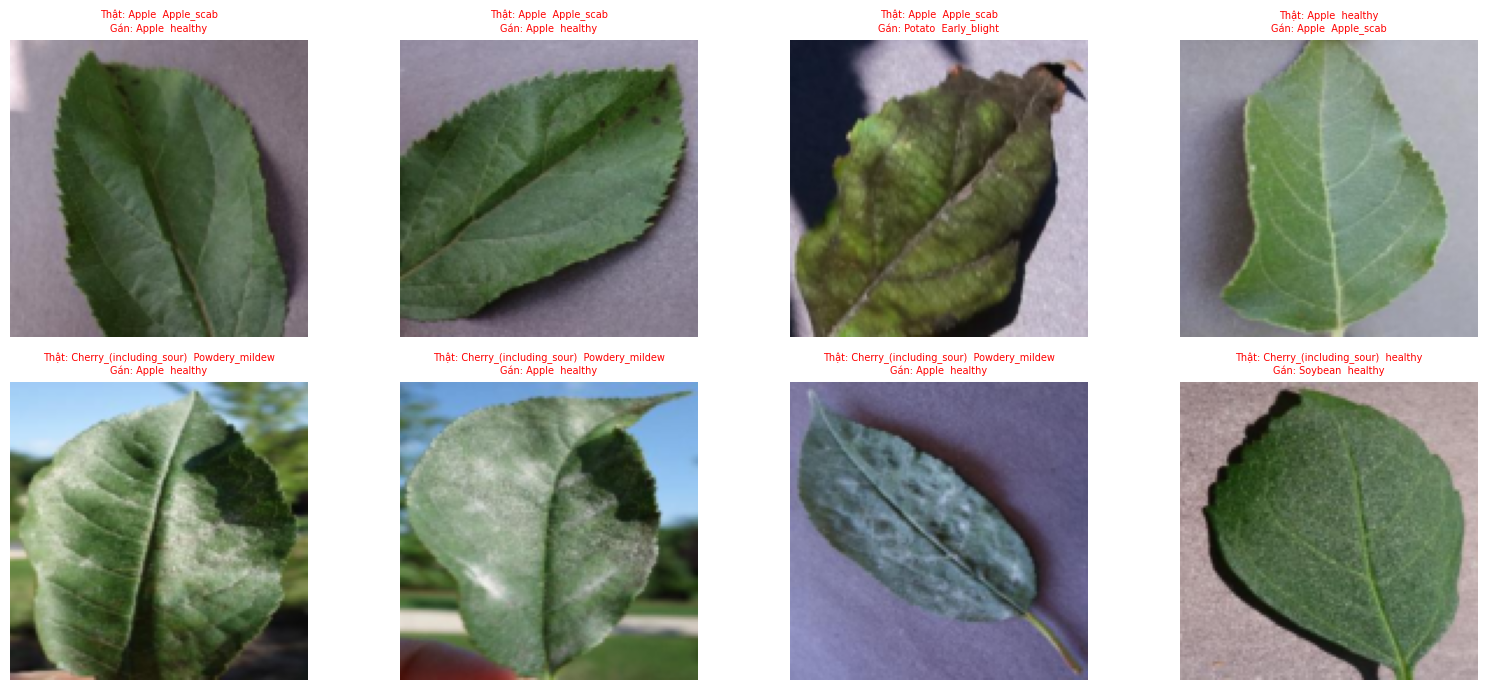

In [20]:
wrong = pseudo_labels != true_of_pseudo
pairs = Counter(zip(true_of_pseudo[wrong], pseudo_labels[wrong])).most_common(8)
print("Các cặp nhãn sai hay gặp nhất (thật → sai):")
for (t, pr), n in pairs:
    print(f"  {n:3d}x  {class_names[t]}  →  {class_names[pr]}")

# Hiển thị vài ảnh bị gán sai
w_idx = np.where(wrong)[0][:8]
if len(w_idx):
    plt.figure(figsize=(16, 7))
    for k, j in enumerate(w_idx):
        plt.subplot(2, 4, k + 1)
        plt.imshow(X[int(pseudo_idx[j])].permute(1, 2, 0).cpu()); plt.axis("off")
        plt.title(f"Thật: {class_names[true_of_pseudo[j]].replace('___','  ')}\n"
                  f"Gán: {class_names[pseudo_labels[j]].replace('___','  ')}", fontsize=7, color="red")
    plt.tight_layout(); plt.show()